In [104]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('/content/Mall_Customers.csv')
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [105]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6


In [106]:
#last 3 rows
print(df.tail(3))

     CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
197         198   Male   32                 126                      74
198         199   Male   32                 137                      18
199         200   Male   30                 137                      83


In [107]:
#number of rows and columns
print(df.shape)
#dimension
print(df.ndim)

(200, 5)
2


In [108]:
#statistical summary
print(df.describe())

       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.000000               73.000000
max    200.000000   70.000000          137.000000               99.000000


In [109]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


In [110]:
#number of unique values in each columns
print(df.nunique())

CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64


In [111]:
#datatypes
print(df.dtypes)

CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [112]:
#column names
print(df.columns)
#non-numerical columns names
print(df.select_dtypes(include=object).columns)
#numerical columns names
print(df.select_dtypes(exclude=object).columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')
Index(['Gender'], dtype='object')
Index(['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'], dtype='object')


In [113]:
#duplicate values
print(df.duplicated().sum())

0


In [114]:
#null values
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [115]:
#DATA CLEANING

#min and max values of numerical columns
num=df.select_dtypes(exclude=object).columns
for i in num:
  print(i,"min:",df[i].min())
  print(i,"max:",df[i].max())


CustomerID min: 1
CustomerID max: 200
Age min: 18
Age max: 70
Annual Income (k$) min: 15
Annual Income (k$) max: 137
Spending Score (1-100) min: 1
Spending Score (1-100) max: 99


In [116]:
#dropping unwanted column
df=df.drop('CustomerID',axis=1)
df

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
...,...,...,...,...
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74
198,Male,32,137,18


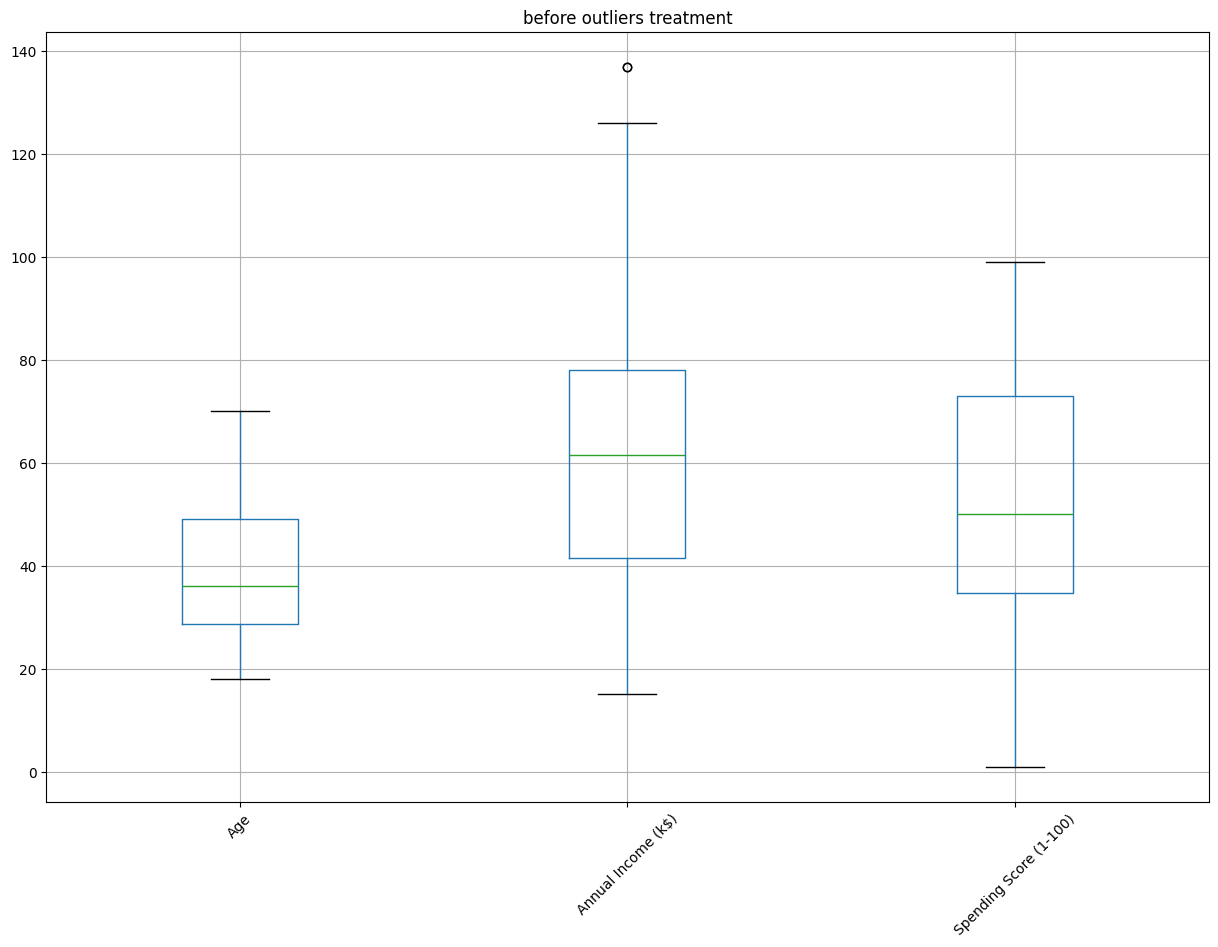

In [117]:
#OUTLIERS

#A. BOXPLOT TO CHECK OUTLIERS
plt.figure(figsize=(15,10))
df.select_dtypes(exclude=object).boxplot()
plt.xticks(rotation=45)
plt.title("before outliers treatment")
plt.show()

In [118]:
#B. NUMBER OF OUTLIERS IN EACH COLUMN
num=df.select_dtypes(exclude=object).columns
for i in num:
  Q1=df[i].quantile(0.25)
  Q3=df[i].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  outliers=df[(df[i]<lower)|(df[i]>upper)]
  print(i,"outliers:",len(outliers))

Age outliers: 0
Annual Income (k$) outliers: 2
Spending Score (1-100) outliers: 0


In [119]:
#C. TREATING OUTLIERS
for i in num:
  Q1=df[i].quantile(0.25)
  Q3=df[i].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  df[i]=df[i].clip(lower,upper)

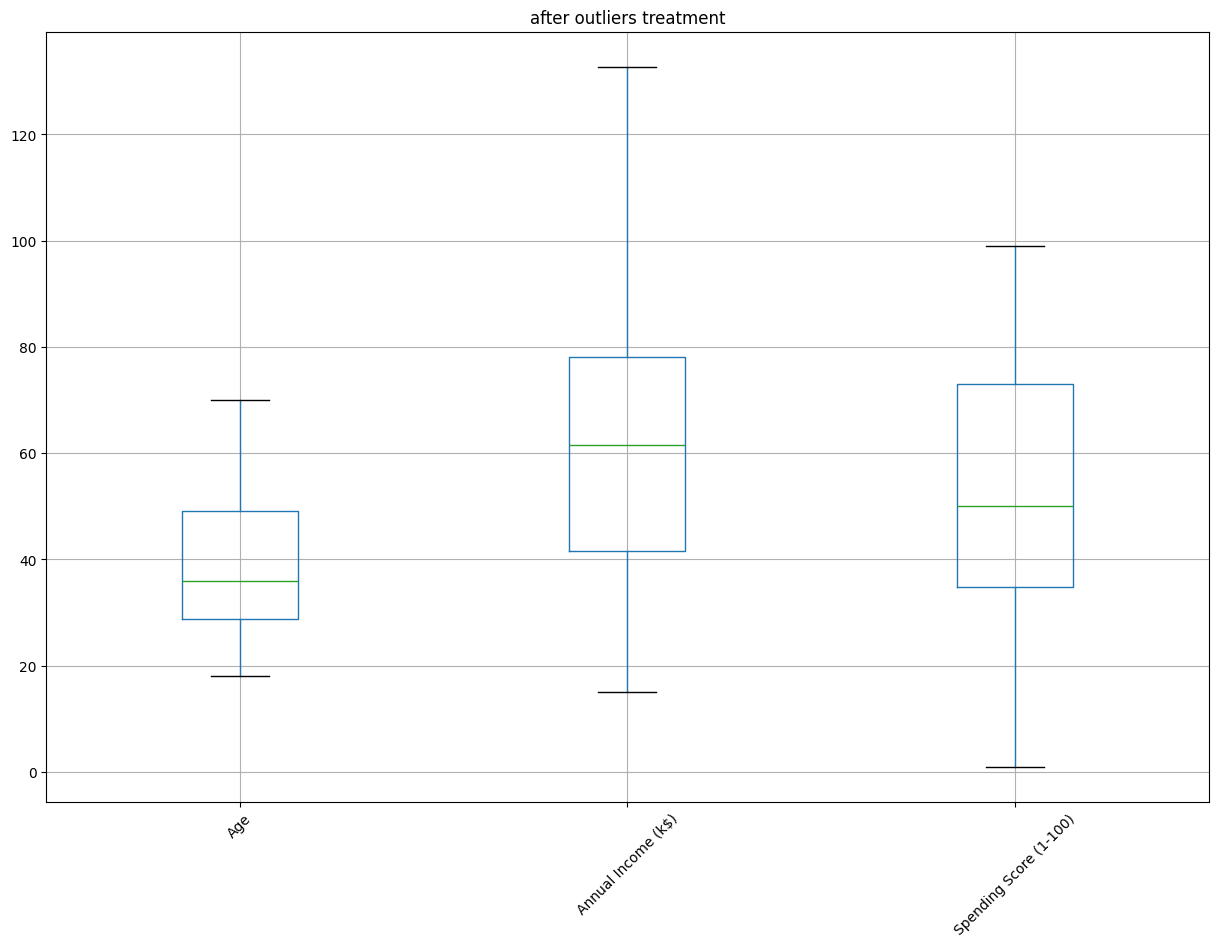

In [120]:
#D. BOXPLOT AFTER OUTLIERS TREATMENT
plt.figure(figsize=(15,10))
df.select_dtypes(exclude=object).boxplot()
plt.xticks(rotation=45)
plt.title("after outliers treatment")
plt.show()

In [121]:
#ONE-HOT ENCODDING
df=pd.get_dummies(df,columns=['Gender'],drop_first=True)
df

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15.00,39,True
1,21,15.00,81,True
2,20,16.00,6,False
3,23,16.00,77,False
4,31,17.00,40,False
...,...,...,...,...
195,35,120.00,79,False
196,45,126.00,28,False
197,32,126.00,74,True
198,32,132.75,18,True


In [122]:
#input selection
x=df
x

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15.00,39,True
1,21,15.00,81,True
2,20,16.00,6,False
3,23,16.00,77,False
4,31,17.00,40,False
...,...,...,...,...
195,35,120.00,79,False
196,45,126.00,28,False
197,32,126.00,74,True
198,32,132.75,18,True


In [123]:
#feature scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled

array([[-1.42456879, -1.74542941, -0.43480148,  1.12815215],
       [-1.28103541, -1.74542941,  1.19570407,  1.12815215],
       [-1.3528021 , -1.70708307, -1.71591298, -0.88640526],
       [-1.13750203, -1.70708307,  1.04041783, -0.88640526],
       [-0.56336851, -1.66873673, -0.39597992, -0.88640526],
       [-1.20926872, -1.66873673,  1.00159627, -0.88640526],
       [-0.27630176, -1.6303904 , -1.71591298, -0.88640526],
       [-1.13750203, -1.6303904 ,  1.70038436, -0.88640526],
       [ 1.80493225, -1.59204406, -1.83237767,  1.12815215],
       [-0.6351352 , -1.59204406,  0.84631002, -0.88640526],
       [ 2.02023231, -1.59204406, -1.4053405 ,  1.12815215],
       [-0.27630176, -1.59204406,  1.89449216, -0.88640526],
       [ 1.37433211, -1.55369772, -1.36651894, -0.88640526],
       [-1.06573534, -1.55369772,  1.04041783, -0.88640526],
       [-0.13276838, -1.55369772, -1.44416206,  1.12815215],
       [-1.20926872, -1.55369772,  1.11806095,  1.12815215],
       [-0.27630176, -1.

In [124]:
#FINDING INERTIA OF CURRESPONDING K VALUES
#wcss-within clusters sum of square
from sklearn.cluster import KMeans
wcss=[]
for i in range(2,11):
  kmeans=KMeans(n_clusters=i,init='k-means++',random_state=41)
  kmeans.fit(x_scaled)
  wcss.append(kmeans.inertia_)
wcss


[588.8027143528252,
 494.93533456285974,
 417.375317711066,
 327.6893324628651,
 289.80426033110695,
 251.53574136244163,
 199.29385158849323,
 175.80390335027167,
 169.70894078921503]

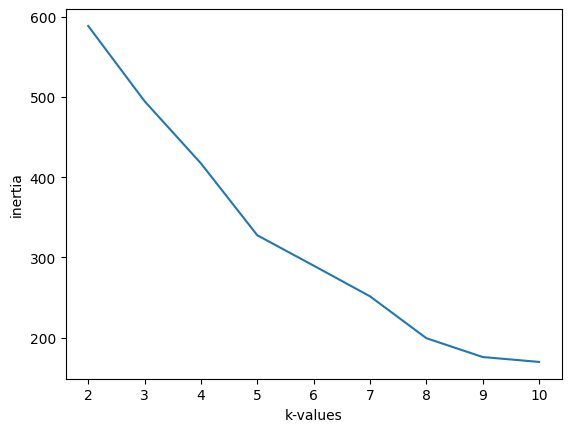

In [125]:
#ELBOW METHOD
plt.plot(range(2,11),wcss)
plt.xlabel("k-values")
plt.ylabel("inertia")
plt.show()

In [126]:
#KMEANS MODEL BUILDING
kmeans=KMeans(n_clusters=8,init="k-means++",random_state=41)
clust=kmeans.fit(x_scaled)
labels=clust.labels_
print(labels)


[3 3 5 5 5 5 0 5 4 5 4 5 0 5 4 3 5 3 4 5 3 3 0 3 0 3 0 3 0 5 4 5 4 3 0 5 0
 5 0 5 0 3 4 5 0 5 0 5 5 5 0 3 5 4 0 4 0 4 5 4 4 3 0 0 4 3 0 0 3 5 4 0 0 0
 4 3 0 4 5 0 4 3 4 0 5 4 0 5 5 0 0 3 4 0 5 3 0 5 4 3 5 0 4 3 4 5 0 4 4 4 4
 5 6 3 5 5 0 0 0 0 3 6 1 7 6 1 2 7 4 7 2 7 6 1 2 1 6 7 2 1 6 7 6 1 2 7 2 1
 6 7 2 7 6 1 6 1 2 1 2 1 6 1 2 1 2 1 2 1 6 7 2 7 2 7 6 1 2 7 2 7 6 1 2 1 6
 7 6 7 6 1 6 1 2 1 6 1 6 7 2 7]


In [127]:
df['cluster']=kmeans.labels_
df

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,cluster
0,19,15.00,39,True,3
1,21,15.00,81,True,3
2,20,16.00,6,False,5
3,23,16.00,77,False,5
4,31,17.00,40,False,5
...,...,...,...,...,...
195,35,120.00,79,False,1
196,45,126.00,28,False,6
197,32,126.00,74,True,7
198,32,132.75,18,True,2


In [128]:
#PERFORMANCE EVALUATION
from sklearn.metrics import silhouette_samples
print(silhouette_samples(x_scaled,labels))

[ 0.3514462   0.41592571  0.14249932  0.4164223   0.2215365   0.4210858
  0.09408949  0.33345897  0.29877533  0.43139226  0.33286305  0.24629522
  0.33763857  0.44252423  0.02352615  0.45926365  0.03806745  0.48089581
  0.3704085   0.23106786  0.16529711  0.50418641  0.30116648  0.47587176
  0.3959946   0.43592363  0.35522719  0.39964931  0.20312556  0.37111339
  0.33630879  0.48080337  0.25784474  0.35350616  0.36904461  0.40229235
  0.31433115  0.42296338  0.0966018   0.42030508  0.40028405  0.29074126
  0.39039608  0.43237841  0.46165118  0.4840219   0.4525399   0.45009586
  0.35222421  0.28559607  0.47239937  0.43351984  0.39667403  0.46890561
  0.53556612  0.35915661  0.53258931  0.48916056  0.47706747  0.51238686
  0.46067499  0.53259914  0.3959403   0.5011135   0.53117766  0.50605503
  0.3108312   0.38449198  0.51114476  0.28361857  0.46987114  0.48282981
  0.51409023  0.49200113  0.54829184  0.43357821  0.37955432 -0.03602135
  0.3952707   0.459946    0.53284359  0.1692204   0.